# Chemical and elastic spinodal decomposition

I evolve a conserved dimensionless composition c on a periodic grid. The bulk energy is c²(1−c)². The chemical potential contains its derivative, a gradient contribution and, in elastic mode, a homogeneous elastic contribution. n is the number of points per direction, dt is the time step, and steps is the number of updates. All model quantities are dimensionless.

I develop this calculation in small steps. I run a cell, inspect its result and test it before adding the next part. Run the cells in order in Jupyter. A code cell defines a part of the calculation or carries it out; defining a function does not run it.

I permit free noncommercial teaching, learning and demonstrations with acknowledgment. Research and commercial use require my written permission. Earlier licensed releases retain their permissions. [Read the code-use terms](https://saswataiith.github.io/using-my-resources/).

Copyright (c) 2026 Saswata Bhattacharyya.

I choose the mean composition explicitly: `c0 = 0.5`. The small seeded perturbation is added once, at the start. The printed mean checks that the initialization retains this chosen composition. For the chemical free energy $f(c)=c^2(1-c)^2$, its inflection points are $(3-\sqrt{3})/6 \approx 0.2113$ and $(3+\sqrt{3})/6 \approx 0.7887$. Between them, $f^{\prime\prime}(c_0)<0$, so sufficiently long-wavelength composition fluctuations grow. Elasticity adds a further penalty and can narrow this unstable range. Outside the chemical spinodal, small fluctuations decay; nucleation requires a sufficiently large fluctuation or a suitable seed.

Initial random perturbations are different from sustained thermal fluctuations. A thermal Cahn–Hilliard–Cook model uses a conserved random flux, with Gaussian white-noise statistics in the ideal continuum model and amplitude fixed by fluctuation–dissipation. Its discretization depends on cell size and time step. I do not add thermal noise during the evolution here. [Cook’s original paper](https://doi.org/10.1016/0001-6160(70)90144-6).

## Follow the energy, slope and curvature

I begin with the curves, mark the mean composition and then look at the curvature. The last panel joins two nearby compositions in equal amounts. Their mean stays at $c_0$, while their mean chemical energy is $\bar f=[f(c_0-\delta c)+f(c_0+\delta c)]/2$. Here $c_0=0.5$ and $\delta c=0.04$.

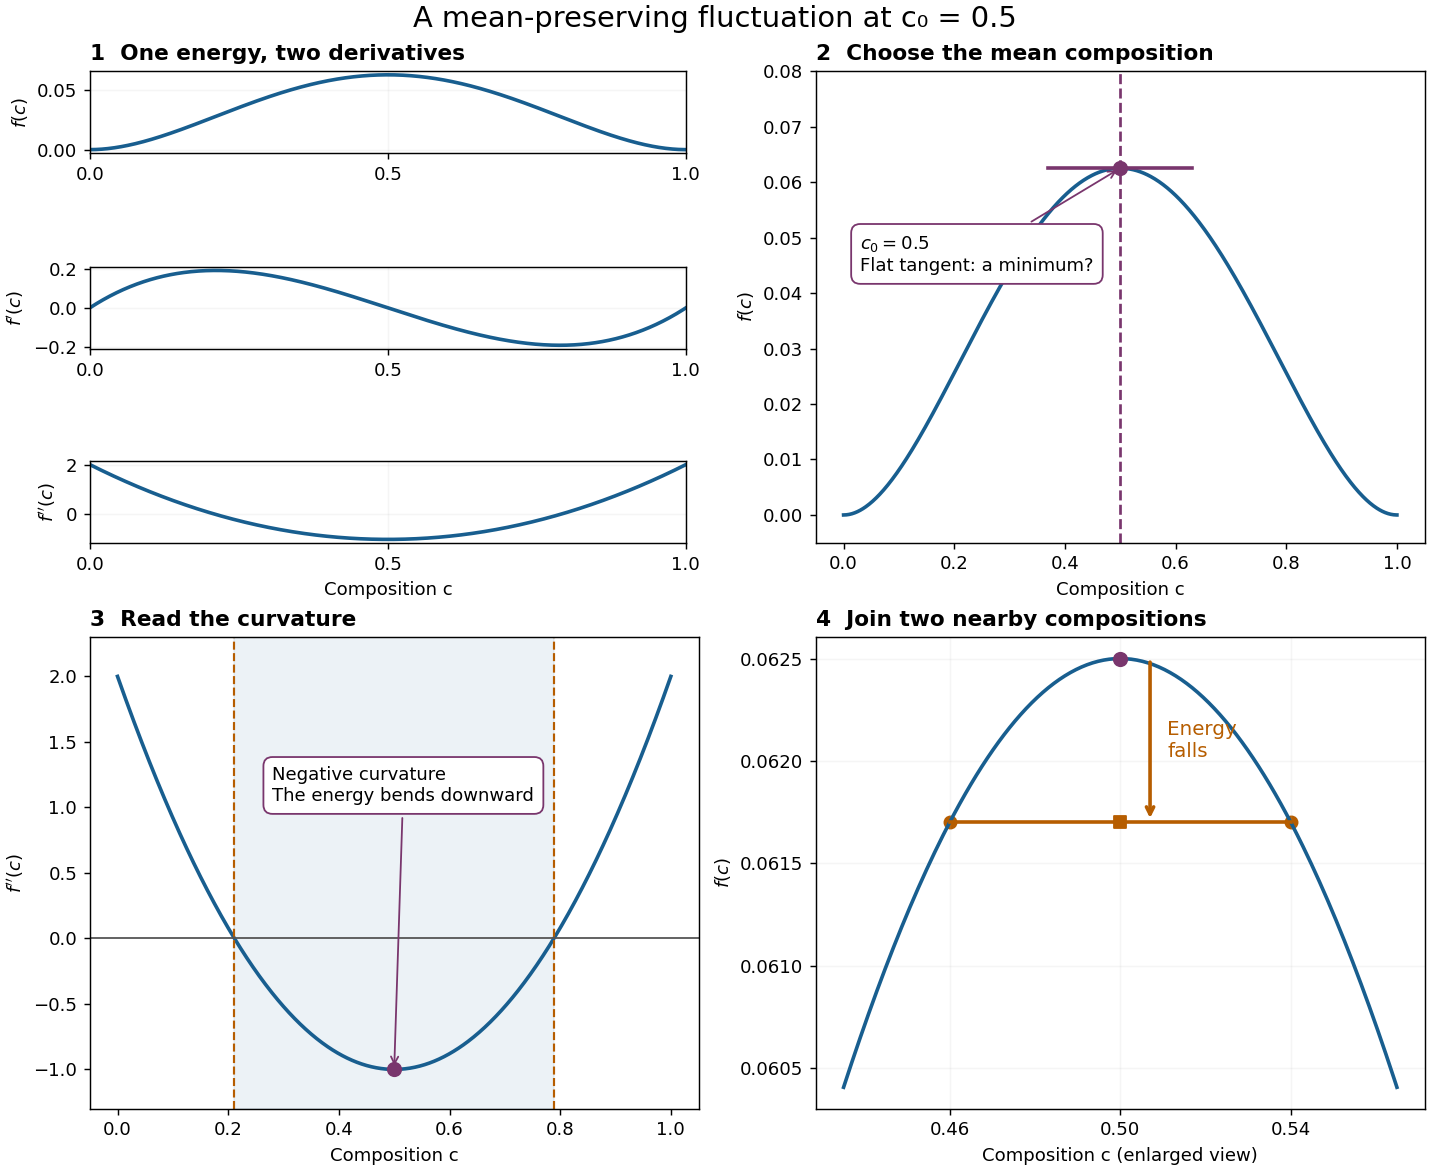

The orange square is the average energy of the two compositions; the purple point is the uniform composition. The downward arrow shows the chemical energy decrease. The connecting line is not the equilibrium common tangent. I compare the bulk chemical term here, before interfacial and elastic costs. The [interactive lesson](https://saswataiith.github.io/resources/step-by-step/phase-field/#mean-composition) lets me repeat this comparison at other compositions.

## Step 1: Prepare the Python environment

I install the packages listed in the next cell once in the same environment as the notebook. In Jupyter or Colab, remove the comment marker from the installation line below if a package is missing. NumPy stores arrays and evaluates numerical operations. Matplotlib displays plots. Pillow reads and writes images. This installation does not change the model parameters.

In [1]:
# %pip install numpy matplotlib
import numpy as np
assert np.isfinite(np.array([0.0, 1.0])).all()
print("NumPy is ready:", np.__version__)

NumPy is ready: 2.1.3


## Step 2: Input values

I retain the default values from the original calculation. The output name locates the files written by this notebook.

In [2]:
mode = 'chemical'
c0 = 0.5
output = 'phase-field-results'
n = None
dt = 0.2
steps = 2000

## Step 3: Prepare the next part of the calculation

I define the following operations. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [3]:
import sys
from pathlib import Path
import numpy as np

## Step 4: Calculate the elastic kernel

I calculate B for each wave-vector direction from the stiffness constants and a dilatational misfit. \(C_{11}\), \(C_{12}\) and \(C_{44}\) are the stiffness constants, and eigenstrain is the prescribed stress-free strain. This example uses dimensionless stiffness and strain. The zero mode corresponds to the specified macroscopic condition; it is not a directional mode.

In [4]:
def kernel(kx, ky, c11=4.0, c12=2.0, c44=3.0, eigenstrain=0.2):
    """B = E:C:E - (sigma0.n).Q^-1.(sigma0.n), E=eigenstrain*I.
    Q_ik=C_ijkl*n_j*n_l; Q11=C11*nx²+C44*ny² (not C12).
    This is a 2D constitutive model, not a reduction with epsilon_zz eigenstrain.
    """
    k2 = kx * kx + ky * ky
    radius = np.sqrt(np.where(k2 == 0, 1.0, k2))
    nx, ny = (kx / radius, ky / radius)
    q11 = c11 * nx * nx + c44 * ny * ny
    q22 = c44 * nx * nx + c11 * ny * ny
    q12 = (c12 + c44) * nx * ny
    det = q11 * q22 - q12 * q12
    det = np.where(k2 == 0, 1.0, det)
    stress = (c11 + c12) * eigenstrain
    b = 2 * (c11 + c12) * eigenstrain ** 2 - stress ** 2 * (q22 * nx * nx - 2 * q12 * nx * ny + q11 * ny * ny) / det
    return np.where(k2 == 0, 0.0, b)

## Step 5: Set up the Fourier grid

I construct Fourier wave numbers from the grid spacing and domain size. A Laplacian multiplies each Fourier mode by minus its squared wave number. The zero Fourier mode represents the spatial mean.

In [5]:
out = Path(output)
out.mkdir(parents=True, exist_ok=True)
if n is None:
    n = 256 if mode == 'elastic' else 64
if mode not in ('chemical', 'elastic'):
    raise ValueError('Choose chemical or elastic')
k = 2 * np.pi * np.fft.fftfreq(n)
kx, ky = np.meshgrid(k, k, indexing='ij')
k2 = kx * kx + ky * ky
b = kernel(kx, ky) if mode == 'elastic' else np.zeros_like(k2)
opposite_index = -np.arange(n) % n

## Step 6: Set up the Fourier grid

I construct Fourier wave numbers from the grid spacing and domain size. A Laplacian multiplies each Fourier mode by minus its squared wave number. The zero Fourier mode represents the spatial mean.

I use NumPy’s random generator with seed 714. Reusing the seed reproduces the initial field in this environment. I subtract the perturbation’s mean to retain mean composition 0.5.

A real composition field has Fourier coefficients at opposite wave vectors. For each wave vector \(\mathbf{k}\), the coefficient at \(-\mathbf{k}\) is its complex conjugate: the real parts are equal and the imaginary parts have opposite signs,
\[\widehat c(-\mathbf{k})=\widehat c(\mathbf{k})^*.\]
Here the star means complex conjugation. This conjugate symmetry is what allows the inverse Fourier transform to recover a real field.

The elastic kernel in this calculation is real. To preserve that conjugate symmetry during an update, it must have the same value at opposite wave vectors: \(B(-\mathbf{k})=B(\mathbf{k})\). This symmetry already holds analytically for the dilatational kernel used here. I make it explicit in the stored numerical array by replacing the coefficients at opposite wave vectors with their average.

For eight grid points, the picture separates the wave number from its position in the NumPy array. The arrows connect opposite wave numbers; $L$ is the periodic domain length. The dashed $+4$ repeats the $-4$ grid mode, not an extra array entry.

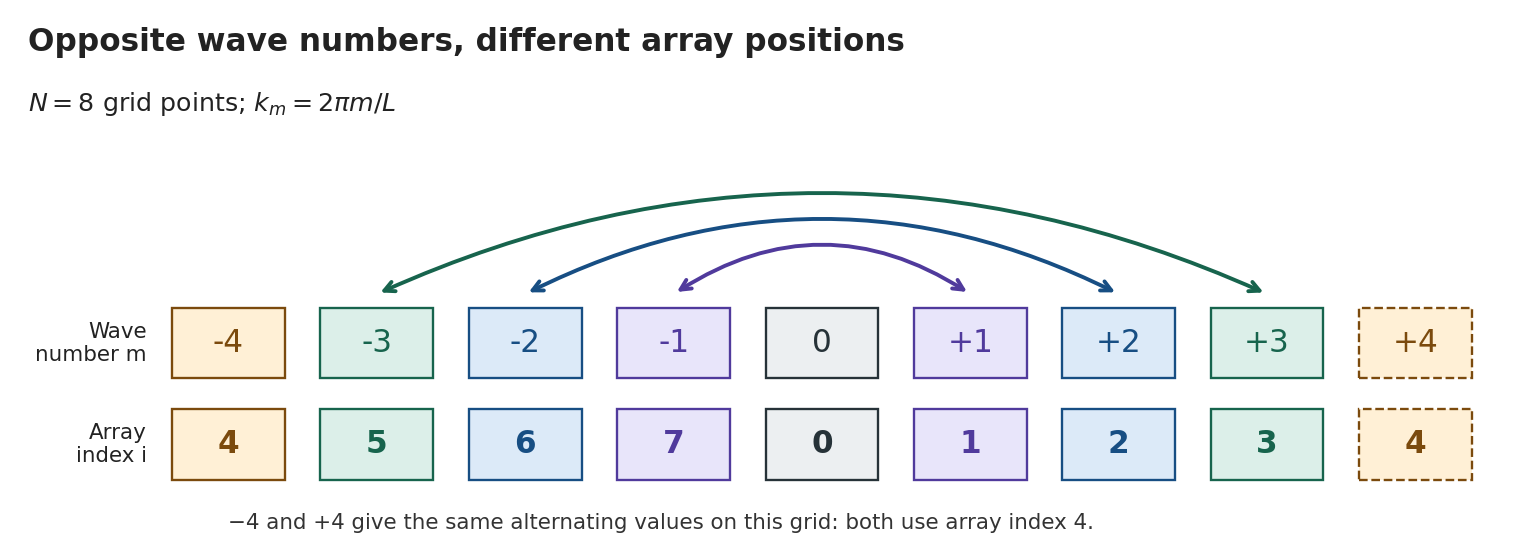

For example, $m=1$ and $m=-1$ are stored at indices 1 and 7. The modulo operation finds this opposite index. In two dimensions I apply the same rule to both directions, so index (1, 2) maps to (7, 6). I average the two kernel values so they agree.

In [6]:
# Give opposite wave vectors the same real kernel value.
b = 0.5 * (b + b[np.ix_(opposite_index, opposite_index)])
seed = 714
rng = np.random.default_rng(seed)
noise = 0.02 * (rng.random((n, n)) - 0.5)
noise -= noise.mean()
c = c0 + noise
initial_mean = c.mean()
print("Mean composition =", initial_mean)
records = []
denominator = 1 + dt * k2 * (k2 + b)

Mean composition = 0.5


## Step 7: Define record

I define this operation before calling it. I keep its arguments explicit so I can test it separately.

In [7]:
def record(step):
    h = np.fft.fft2(c)
    energy = np.mean(c * c * (1 - c) ** 2) + 0.5 * np.sum((k2 + b) * np.abs(h) ** 2) / n ** 4
    records.append([step * dt, c.mean(), energy, c.min(), c.max()])
    np.savetxt(out / f'field_{step:04d}.csv', c, delimiter=',')

## Step 8: Prepare the next part of the calculation

I define the following operations. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [8]:
record(0)

## Step 9: Advance the field and record the result

I apply the update in its original order. I record the mean, energy or other diagnostics at the specified intervals. I do not clip the numerical field. A saved picture is a display of the field, not a substitute for a conservation check.

In [9]:
for step in range(1, steps + 1):
    h = (np.fft.fft2(c) - dt * k2 * np.fft.fft2(2 * c * (1 - c) * (1 - 2 * c))) / denominator
    c = np.fft.ifft2(h).real
    if step % 25 == 0 or step == steps:
        record(step)

## Step 10: My check of this result

I check finite values, conservation or the known reference result as specified below. An assertion stops the notebook if the condition fails. Inspect the quantities and tolerance rather than suppressing a failure.

In [10]:
assert np.isfinite(c).all()
assert abs(c.mean() - initial_mean) < 1e-10
np.savetxt(out / 'diagnostics.csv', records, delimiter=',', header='time,mean,energy_density,min,max', comments='')
print(mode, 'mean drift', abs(c.mean() - initial_mean), 'energy', records[0][2], records[-1][2])

chemical mean drift 2.1094237467877974e-15 energy 0.06259409563917234 0.025080532883736018


## Plot and interpret the result

I plot c without changing its stored values. The color scale is a display choice. The mean checks test conservation, while the sampled energy history helps assess this particular run. It does not prove stability for arbitrary time steps.

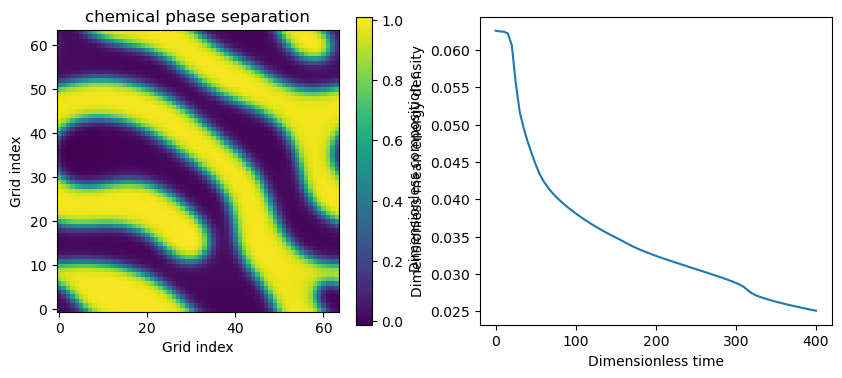

In [11]:
import matplotlib.pyplot as plt
values = np.asarray(records)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
image = axes[0].imshow(c, origin="lower")
fig.colorbar(image, ax=axes[0], label="Dimensionless composition c")
axes[0].set_title(mode + " phase separation")
axes[0].set_xlabel("Grid index")
axes[0].set_ylabel("Grid index")
axes[1].plot(values[:, 0], values[:, 2])
axes[1].set_xlabel("Dimensionless time")
axes[1].set_ylabel("Dimensionless mean energy density")
plt.show()

## Step 11: Read the saved fields for the movie

I read the CSV snapshots in simulation-time order. These are the fields already calculated above; making the movie does not rerun the evolution.

In [12]:
snapshot_steps = [0] + list(range(25, steps + 1, 25))
if snapshot_steps[-1] != steps:
    snapshot_steps.append(steps)
times = [step * dt for step in snapshot_steps]
saved_fields = [np.loadtxt(out / f"field_{step:04d}.csv", delimiter=",")
                for step in snapshot_steps]
print("Saved frames:", len(saved_fields))

Saved frames: 81


## Step 12: Make an animation

I create one image with a fixed composition scale. The function draw_frame(index) replaces its displayed values with the saved array at that index and updates the time label. FuncAnimation calls this function once for each saved frame. The 125 millisecond interval gives eight frames per second. This controls playback speed, not the numerical time step. I retain the movie variable so the animation object remains available. Closing the static figure prevents an extra still plot from appearing in the notebook.

In [13]:
from matplotlib.animation import FuncAnimation

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
image = ax.imshow(saved_fields[0], origin="lower", vmin=0, vmax=1,
                  cmap="viridis", interpolation="nearest")
fig.colorbar(image, ax=ax, label="Composition c (dimensionless)")
ax.set_xlabel("y grid index")
ax.set_ylabel("x grid index")
time_label = ax.set_title(f"{mode}: time = 0")

def draw_frame(index):
    image.set_data(saved_fields[index])
    time_label.set_text(f"{mode}: time = {times[index]:g}")
    return image, time_label

movie = FuncAnimation(fig, draw_frame, frames=len(times),
                      interval=125, repeat=True)
plt.close(fig)

## Step 13: Save and display the movie

I use Matplotlib’s FFMpegWriter to encode the frames as an MP4. This requires the separate FFmpeg program on the system PATH, in addition to NumPy, Matplotlib and IPython. If it is missing in a Colab/Linux environment, I can install it in a separate cell with `!apt-get -qq install ffmpeg`; on macOS with Homebrew, the terminal command is `brew install ffmpeg`. IPython’s Video displays the saved file inside Jupyter or Colab. Setting embed=True stores the movie in the notebook output, so the notebook can carry the result with it. The controls allow playback and pause; loop repeats playback, not the physical evolution.

In [14]:
from matplotlib.animation import FFMpegWriter
from IPython.display import Video, display

movie_path = str(out / "phase-field.mp4")
movie.save(movie_path, writer=FFMpegWriter(fps=8), dpi=120)
print("Saved movie:", movie_path)
display(Video(movie_path, embed=True,
              html_attributes="controls loop muted playsinline"))

Saved movie: phase-field-results/phase-field.mp4


## Step 14: Review and extend the calculation

I first restart the kernel and run all the required cells. Then I change one input, predict its effect and compare the result with that prediction. A successful check establishes the tested property; it does not establish convergence or equilibrium. I include the complete calculation in this notebook; no separate script is needed. For a standalone implementation, [email me explaining which code you need, why you need it and how you intend to use it](https://saswataiith.github.io/using-my-resources/#request-code).